# Proyek Akhir Pembelajaran Mesin (INF62325)
## Tahap 3 — Varian 1 (Dasar / Baseline): Klasifikasi k-NN vs Naive Bayes (`03_varian_1.ipynb`)

* **Mata Kuliah**: Pembelajaran Mesin (INF62325) — Program Studi S1 Informatika, UIN Siber Syekh Nurjati Cirebon
* **Dosen Pengampu**: Ardi Susanto, S.Kom., M.Cs.
* **Kelas**: Informatika 5C
* **Paket Dataset**: *Default of Credit Card Clients* (UCI Machine Learning Repository, ID: 350)
* **Anggota Penanggung Jawab Varian 1 (Dasar)**: Muhammad 'Arif Nur Shidiq (`2488010022`)
* **Tujuan Varian 1**:
  Membangun model klasifikasi **k-Nearest Neighbors (k-NN)** dan **Gaussian Naive Bayes** menggunakan konfigurasi **dasar (default)** sebagai tolok ukur (*baseline*) untuk dibandingkan dengan Varian 2 (penyetelan parameter & perlakuan data) dan Varian 3 (pemilihan fitur).

### Spesifikasi Konfigurasi Varian 1 (Dasar)
* **Dataset**: Seluruh fitur dasar hasil prapemrosesan dari `02_praproses.ipynb` (`data_praproses_dasar.csv` — 24 fitur dasar bersih dengan kolom target **`Y`** selaras `01_Eksplorasi.ipynb`).
* **Pembagian Data**: 80% Data Latih, 20% Data Uji (`stratify=y`, `random_state=42`).
* **Penskalaan**: `StandardScaler` selektif pada fitur numerik/ordinal (*fit* pada data latih, *transform* pada data latih dan uji).
* **Model 1**: `KNeighborsClassifier(n_neighbors=5)` (default Euclidean distance, bobot uniform).
* **Model 2**: `GaussianNB()` (default `var_smoothing=1e-9`, prior empiris).

### Langkah 1 — Impor Pustaka & Pemuatan Dataset Hasil Praproses
Notebook ini secara otomatis memuat `data_praproses_dasar.csv` keluaran `02_praproses.ipynb` (dengan target **`Y`** selaras `01_Eksplorasi.ipynb`). Jika berkas belum tersedia di sesi aktif, sel di bawah otomatis menjalankan pipeline pemuatan (`ucimlrepo` ID 350 / lokal) & prapemrosesan dasar yang identik dengan `02_praproses.ipynb`.

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
print("Pustaka pemodelan Varian 1 berhasil dimuat.")

Pustaka pemodelan Varian 1 berhasil dimuat.


In [2]:
UCI_FEATURE_MAP = {
    'X1': 'LIMIT_BAL', 'X2': 'SEX', 'X3': 'EDUCATION', 'X4': 'MARRIAGE', 'X5': 'AGE',
    'X6': 'PAY_0', 'X7': 'PAY_2', 'X8': 'PAY_3', 'X9': 'PAY_4', 'X10': 'PAY_5', 'X11': 'PAY_6',
    'X12': 'BILL_AMT1', 'X13': 'BILL_AMT2', 'X14': 'BILL_AMT3',
    'X15': 'BILL_AMT4', 'X16': 'BILL_AMT5', 'X17': 'BILL_AMT6',
    'X18': 'PAY_AMT1', 'X19': 'PAY_AMT2', 'X20': 'PAY_AMT3',
    'X21': 'PAY_AMT4', 'X22': 'PAY_AMT5', 'X23': 'PAY_AMT6',
    'x1': 'LIMIT_BAL', 'x2': 'SEX', 'x3': 'EDUCATION', 'x4': 'MARRIAGE', 'x5': 'AGE',
    'x6': 'PAY_0', 'x7': 'PAY_2', 'x8': 'PAY_3', 'x9': 'PAY_4', 'x10': 'PAY_5', 'x11': 'PAY_6',
    'x12': 'BILL_AMT1', 'x13': 'BILL_AMT2', 'x14': 'BILL_AMT3',
    'x15': 'BILL_AMT4', 'x16': 'BILL_AMT5', 'x17': 'BILL_AMT6',
    'x18': 'PAY_AMT1', 'x19': 'PAY_AMT2', 'x20': 'PAY_AMT3',
    'x21': 'PAY_AMT4', 'x22': 'PAY_AMT5', 'x23': 'PAY_AMT6'
}

def load_credit_card_dataset():
    """Memuat dataset Default of Credit Card Clients (ID 350) selaras 01_Eksplorasi.ipynb."""
    try:
        from ucimlrepo import fetch_ucirepo
        dataset = fetch_ucirepo(id=350)
        df = pd.concat([dataset.data.features, dataset.data.targets], axis=1)
        print("Memuat dataset dari ucimlrepo (ID=350) — selaras 01_Eksplorasi.ipynb")
        return df
    except Exception:
        pass

    local_candidates = [
        'default of credit card clients.xls',
        'default_of_credit_card_clients.xls',
        'default_of_credit_card_clients.csv',
        'UCI_Credit_Card.csv'
    ]
    for fname in local_candidates:
        if os.path.exists(fname):
            print(f"Memuat dataset dari berkas lokal: {fname}")
            if fname.endswith('.xls') or fname.endswith('.xlsx'):
                return pd.read_excel(fname, header=1)
            return pd.read_csv(fname)

    from sklearn.datasets import fetch_openml
    bunch = fetch_openml(data_id=42477, as_frame=True, parser="auto")
    df = bunch.frame.copy()
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    print("Memuat dataset dari OpenML (ID=42477).")
    return df

def clean_raw_credit_df(df_raw):
    """Membersihkan struktur kolom, duplikat, dan kategori anomali selaras 02_praproses.ipynb."""
    df = df_raw.copy()
    for id_col in ['ID', 'id', 'Id']:
        if id_col in df.columns:
            df = df.drop(columns=[id_col])

    df = df.rename(columns={k: v for k, v in UCI_FEATURE_MAP.items() if k in df.columns})
    if 'PAY_1' in df.columns and 'PAY_0' not in df.columns:
        df = df.rename(columns={'PAY_1': 'PAY_0'})

    target_candidates = [
        'Y', 'y', 'default payment next month',
        'default.payment.next.month', 'default_payment_next_month', 'default', 'target'
    ]
    for tc in target_candidates:
        if tc in df.columns:
            if tc != 'Y':
                df = df.rename(columns={tc: 'Y'})
            break

    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    df = df.dropna().drop_duplicates().reset_index(drop=True)
    df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4}).astype(int)
    df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3}).astype(int)
    df['SEX'] = df['SEX'].astype(int)
    df['Y'] = df['Y'].astype(int)
    return df

if os.path.exists("data_praproses_dasar.csv"):
    print("Memuat dataset hasil praproses dari 02_praproses.ipynb: data_praproses_dasar.csv")
    df_base = pd.read_csv("data_praproses_dasar.csv")
    if 'Y' not in df_base.columns:
        for alt in ['default', 'default_payment_next_month', 'default payment next month']:
            if alt in df_base.columns:
                df_base = df_base.rename(columns={alt: 'Y'})
                break
else:
    print("Berkas data_praproses_dasar.csv belum ditemukan, menjalankan prapemrosesan otomatis...")
    df_raw = load_credit_card_dataset()
    df_clean = clean_raw_credit_df(df_raw)
    df_base = pd.get_dummies(df_clean, columns=['SEX', 'MARRIAGE'], drop_first=True, dtype=int)
    df_base.to_csv("data_praproses_dasar.csv", index=False)

print(f"Dimensi data siap latih: {df_base.shape[0]} baris x {df_base.shape[1]} kolom (Target: Y)")
display(df_base.head(3))

Memuat dataset hasil praproses dari 02_praproses.ipynb: data_praproses_dasar.csv
Dimensi data siap latih: 29965 baris x 25 kolom (Target: Y)


,LIMIT_BAL,EDUCATION,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,Y,SEX_2,MARRIAGE_2,MARRIAGE_3
0,20000,2,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1,1,0,0
1,120000,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1,1,1,0
2,90000,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0,1,1,0


### Langkah 2 — Pembagian Data (`Train-Test Split`) & Penskalaan (`StandardScaler`)
Membagi dataset menjadi 80% data latih dan 20% data uji secara terstratifikasi (`stratify=y`), kemudian menerapkan `StandardScaler` selektif pada fitur numerik/ordinal (fit hanya pada data latih).

In [3]:
TARGET = 'Y'
X = df_base.drop(columns=[TARGET])
y = df_base[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

ohe_cols = [c for c in X_train.columns if c.startswith(('SEX_', 'MARRIAGE_'))]
num_cols = [c for c in X_train.columns if c not in ohe_cols]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print(f"Jumlah fitur input : {X_train.shape[1]} fitur ({len(num_cols)} numerik/ordinal + {len(ohe_cols)} one-hot)")
print(f"Data latih         : {X_train.shape[0]} sampel")
print(f"Data uji           : {X_test.shape[0]} sampel")

Jumlah fitur input : 24 fitur (21 numerik/ordinal + 3 one-hot)
Data latih         : 23972 sampel
Data uji           : 5993 sampel


### Langkah 3 — Pelatihan & Evaluasi Model 1: k-Nearest Neighbors (k-NN Baseline)
Melatih model `KNeighborsClassifier` dengan parameter standar ($k = 5$, jarak Euclidean, bobot uniform).

In [4]:
t0 = time.time()
knn_base = KNeighborsClassifier(n_neighbors=5)
knn_base.fit(X_train_scaled, y_train)
train_time_knn = time.time() - t0

t1 = time.time()
y_pred_knn = knn_base.predict(X_test_scaled)
y_prob_knn = knn_base.predict_proba(X_test_scaled)[:, 1]
pred_time_knn = time.time() - t1

print("=== HASIL EVALUASI: k-NN BASELINE (k=5) ===")
print(f"Waktu Latih    : {train_time_knn:.4f} detik | Waktu Prediksi: {pred_time_knn:.4f} detik")
print(f"Accuracy       : {accuracy_score(y_test, y_pred_knn):.4f}")
print(f"Precision (1)  : {precision_score(y_test, y_pred_knn):.4f}")
print(f"Recall (1)     : {recall_score(y_test, y_pred_knn):.4f}")
print(f"F1-Score (1)   : {f1_score(y_test, y_pred_knn):.4f}")
print(f"ROC-AUC Score  : {roc_auc_score(y_test, y_prob_knn):.4f}")
print("\nClassification Report (k-NN Baseline):")
print(classification_report(y_test, y_pred_knn, target_names=['Tidak Gagal Bayar (0)', 'Gagal Bayar (1)']))

=== HASIL EVALUASI: k-NN BASELINE (k=5) ===
Waktu Latih    : 0.0089 detik | Waktu Prediksi: 1.3049 detik
Accuracy       : 0.7929
Precision (1)  : 0.5501
Recall (1)     : 0.3522
F1-Score (1)   : 0.4294
ROC-AUC Score  : 0.6967

Classification Report (k-NN Baseline):
                       precision    recall  f1-score   support

Tidak Gagal Bayar (0)       0.83      0.92      0.87      4667
      Gagal Bayar (1)       0.55      0.35      0.43      1326

             accuracy                           0.79      5993
            macro avg       0.69      0.64      0.65      5993
         weighted avg       0.77      0.79      0.78      5993



### Langkah 4 — Pelatihan & Evaluasi Model 2: Gaussian Naive Bayes (Baseline)
Melatih model `GaussianNB` dengan parameter standar.

In [5]:
t0 = time.time()
nb_base = GaussianNB()
nb_base.fit(X_train_scaled, y_train)
train_time_nb = time.time() - t0

t1 = time.time()
y_pred_nb = nb_base.predict(X_test_scaled)
y_prob_nb = nb_base.predict_proba(X_test_scaled)[:, 1]
pred_time_nb = time.time() - t1

print("=== HASIL EVALUASI: GAUSSIAN NAIVE BAYES BASELINE ===")
print(f"Waktu Latih    : {train_time_nb:.4f} detik | Waktu Prediksi: {pred_time_nb:.4f} detik")
print(f"Accuracy       : {accuracy_score(y_test, y_pred_nb):.4f}")
print(f"Precision (1)  : {precision_score(y_test, y_pred_nb):.4f}")
print(f"Recall (1)     : {recall_score(y_test, y_pred_nb):.4f}")
print(f"F1-Score (1)   : {f1_score(y_test, y_pred_nb):.4f}")
print(f"ROC-AUC Score  : {roc_auc_score(y_test, y_prob_nb):.4f}")
print("\nClassification Report (Gaussian Naive Bayes Baseline):")
print(classification_report(y_test, y_pred_nb, target_names=['Tidak Gagal Bayar (0)', 'Gagal Bayar (1)']))

=== HASIL EVALUASI: GAUSSIAN NAIVE BAYES BASELINE ===
Waktu Latih    : 0.0172 detik | Waktu Prediksi: 0.0079 detik
Accuracy       : 0.6966
Precision (1)  : 0.3903
Recall (1)     : 0.6599
F1-Score (1)   : 0.4905
ROC-AUC Score  : 0.7275

Classification Report (Gaussian Naive Bayes Baseline):
                       precision    recall  f1-score   support

Tidak Gagal Bayar (0)       0.88      0.71      0.78      4667
      Gagal Bayar (1)       0.39      0.66      0.49      1326

             accuracy                           0.70      5993
            macro avg       0.64      0.68      0.64      5993
         weighted avg       0.77      0.70      0.72      5993



### Langkah 5 — Visualisasi Confusion Matrix & Kurva ROC
Membandingkan matriks kebingungan (*Confusion Matrix*) serta kurva *Receiver Operating Characteristic* (ROC) antara kedua algoritma baseline.

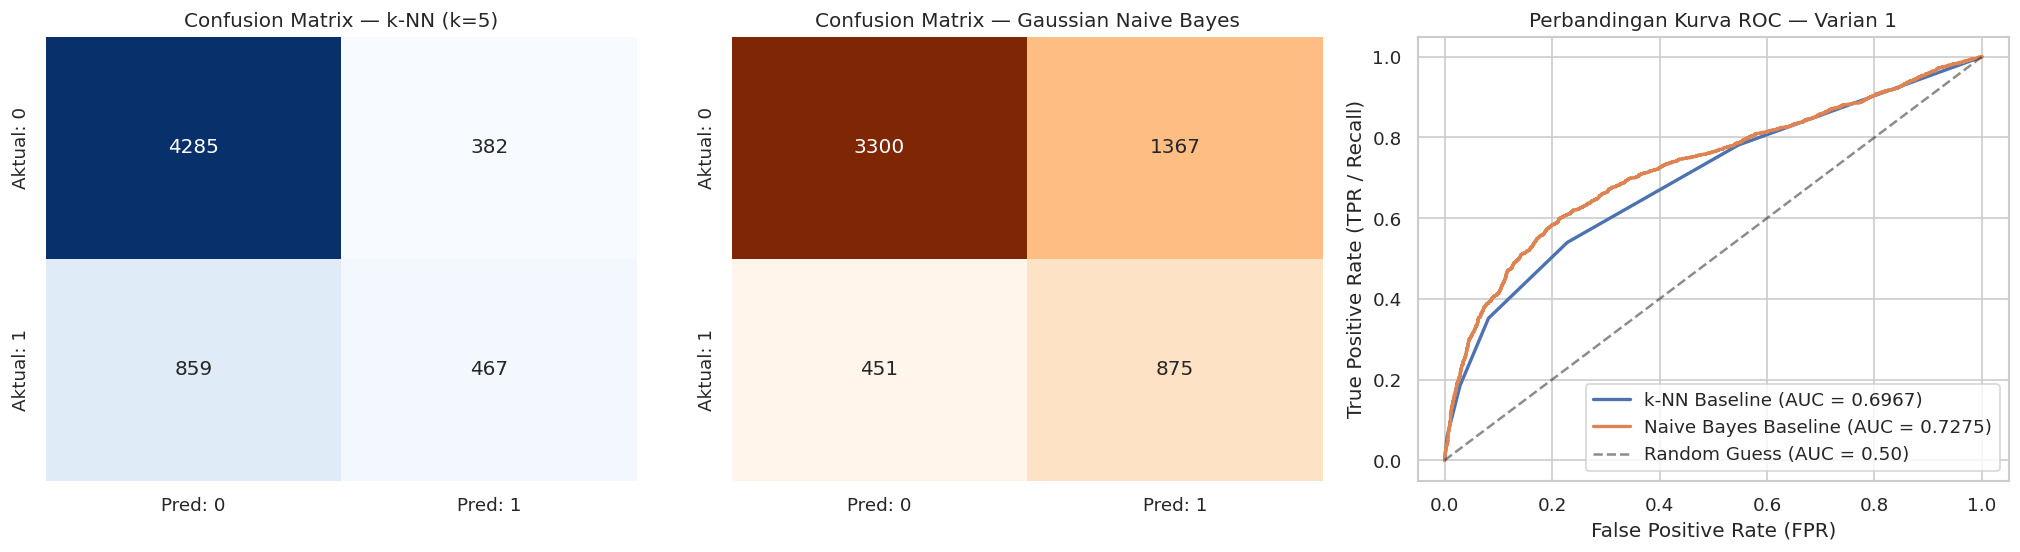

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# Confusion Matrix k-NN
cm_knn = confusion_matrix(y_test, y_pred_knn)
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Pred: 0', 'Pred: 1'], yticklabels=['Aktual: 0', 'Aktual: 1'])
axes[0].set_title('Confusion Matrix — k-NN (k=5)')

# Confusion Matrix Naive Bayes
cm_nb = confusion_matrix(y_test, y_pred_nb)
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=axes[1],
            xticklabels=['Pred: 0', 'Pred: 1'], yticklabels=['Aktual: 0', 'Aktual: 1'])
axes[1].set_title('Confusion Matrix — Gaussian Naive Bayes')

# ROC Curve Comparison
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_prob_knn)
fpr_nb, tpr_nb, _ = roc_curve(y_test, y_prob_nb)

axes[2].plot(fpr_knn, tpr_knn, label=f"k-NN Baseline (AUC = {roc_auc_score(y_test, y_prob_knn):.4f})", linewidth=2)
axes[2].plot(fpr_nb, tpr_nb, label=f"Naive Bayes Baseline (AUC = {roc_auc_score(y_test, y_prob_nb):.4f})", linewidth=2)
axes[2].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Guess (AUC = 0.50)')
axes[2].set_title('Perbandingan Kurva ROC — Varian 1')
axes[2].set_xlabel('False Positive Rate (FPR)')
axes[2].set_ylabel('True Positive Rate (TPR / Recall)')
axes[2].legend(loc='lower right')

plt.tight_layout()
plt.show()

### Langkah 6 — Ringkasan Hasil Varian 1 & Analisis Baseline
Menyusun tabel perbandingan kuantitatif kedua algoritma dan menyimpannya ke `hasil_varian_1.csv` sebagai acuan komparasi dengan Varian 2 dan Varian 3.

In [7]:
hasil_v1 = pd.DataFrame([
    {
        'Varian': 'Varian 1 (Dasar)',
        'Algoritma': 'k-NN (k=5, Euclidean)',
        'Jumlah_Fitur': X_train.shape[1],
        'Best_k': 5,
        'Accuracy': round(accuracy_score(y_test, y_pred_knn), 4),
        'Precision': round(precision_score(y_test, y_pred_knn), 4),
        'Recall': round(recall_score(y_test, y_pred_knn), 4),
        'F1_Score': round(f1_score(y_test, y_pred_knn), 4),
        'ROC_AUC': round(roc_auc_score(y_test, y_prob_knn), 4),
        'Waktu_Prediksi_Detik': round(pred_time_knn, 4),
        'Waktu_Total_Detik': round(train_time_knn + pred_time_knn, 4)
    },
    {
        'Varian': 'Varian 1 (Dasar)',
        'Algoritma': 'Gaussian Naive Bayes (Default)',
        'Jumlah_Fitur': X_train.shape[1],
        'Best_k': None,
        'Accuracy': round(accuracy_score(y_test, y_pred_nb), 4),
        'Precision': round(precision_score(y_test, y_pred_nb), 4),
        'Recall': round(recall_score(y_test, y_pred_nb), 4),
        'F1_Score': round(f1_score(y_test, y_pred_nb), 4),
        'ROC_AUC': round(roc_auc_score(y_test, y_prob_nb), 4),
        'Waktu_Prediksi_Detik': round(pred_time_nb, 4),
        'Waktu_Total_Detik': round(train_time_nb + pred_time_nb, 4)
    }
])

display(hasil_v1)
hasil_v1.to_csv("hasil_varian_1.csv", index=False)
print("Ringkasan Varian 1 disimpan ke hasil_varian_1.csv")

Ringkasan Varian 1 disimpan ke hasil_varian_1.csv


,Varian,Algoritma,Jumlah_Fitur,Best_k,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Waktu_Prediksi_Detik,Waktu_Total_Detik
0,Varian 1 (Dasar),"k-NN (k=5, Euclidean)",24,5.0,0.7929,0.5501,0.3522,0.4294,0.6967,1.3049,1.3138
1,Varian 1 (Dasar),Gaussian Naive Bayes (Default),24,NaN,0.6966,0.3903,0.6599,0.4905,0.7275,0.0079,0.0251


#### Kesimpulan Varian 1 (Baseline)
1. **Perbandingan Akurasi vs Recall**: Pada konfigurasi dasar, **k-NN ($k=5$)** menghasilkan akurasi keseluruhan yang lebih tinggi dibandingkan Gaussian Naive Bayes, namun memiliki nilai *Recall* pada kelas minoritas (`Gagal Bayar = 1`) yang relatif rendah akibat ketidakseimbangan kelas (`77,86%` kelas `0` vs `22,14%` kelas `1`).
2. **Perilaku Gaussian Naive Bayes**: Gaussian Naive Bayes menghasilkan *Recall* yang jauh lebih tinggi untuk mendeteksi nasabah gagal bayar, namun menghasilkan lebih banyak *False Positive* (*Precision* lebih rendah) karena asumsi independensi antarfitur serta distribusi fitur finansial yang miring (*skewed*).
3. **Kecepatan Inferensi**: Naive Bayes melakukan prediksi dalam hitungan milidetik, sedangkan k-NN (*lazy learner*) membutuhkan waktu lebih lama saat prediksi karena menghitung jarak ke seluruh titik data latih.